# Spectral Features Model
The code processes audio data using STFT and Mel-Spectrogram for feature extraction, leveraging frequency-domain representations. The extracted features are flattened and normalized before being fed into a fully connected neural network. The network consists of two dense layers with dropout for regularization and is optimized using binary cross-entropy loss. The model's performance is evaluated using accuracy and a classification report, and a confusion matrix is used to assess prediction results visually. While the model performs moderately well, it lacks advanced techniques such as feature augmentation or contextual embeddings, limiting its overall effectiveness.


1.   **Training accuracy:** 67.10%
2.   **Validation accuracy:** 70.99%
3. **Overall accuracy:** ~71%



In [ ]:
import os
import librosa
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import tensorflow as tf
import matplotlib.pyplot as plt

# Constants
SAMPLE_RATE = 16000
DURATION = 2  # in seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION
AUDIO_PATH = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/Sample_Audio/"
LABEL_FILE = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/output_file.csv"


# Feature Extraction: STFT and Mel-Spectrogram #
def extract_spectral_features(signal, sr=SAMPLE_RATE, n_fft=2048, hop_length=512, n_mels=128):
    """
    Extract spectral features using STFT and Mel-Spectrogram.
    """
    stft = np.abs(librosa.stft(signal, n_fft=n_fft, hop_length=hop_length))
    mel_spectrogram = librosa.feature.melspectrogram(S=stft, sr=sr, n_mels=n_mels)
    log_mel_spectrogram = librosa.power_to_db(mel_spectrogram)
    return log_mel_spectrogram.mean(axis=1)  # Take mean across time




In [ ]:
# Load and Preprocess Data
def load_and_process_data(audio_path, label_file, duration=DURATION):
    """
    Load audio data, extract spectral features, and prepare labels.
    """
    labels_df = pd.read_csv(label_file)
    X, y = [], []

    for _, row in labels_df.iterrows():
        file_path = os.path.join(audio_path, row['filename'])
        label = 1 if row['label'] == 'bonafide' else 0

        try:
            audio, _ = librosa.load(file_path, sr=SAMPLE_RATE, duration=duration)
            audio = np.pad(audio, (0, max(0, SAMPLES_PER_TRACK - len(audio))), mode='constant')
            features = extract_spectral_features(audio)
            X.append(features)
            y.append(label)
        except Exception as e:
            print(f"Error processing {file_path}: {e}")

    return np.array(X), np.array(y)

# Load Dataset
print("Loading dataset...")
X, y = load_and_process_data(AUDIO_PATH, LABEL_FILE)
print(f"Extracted features for {len(X)} samples.")


Loading dataset...
Extracted features for 2462 samples.


Building and training model...
Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5520 - loss: 4.5236 - val_accuracy: 0.6227 - val_loss: 0.6340
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6161 - loss: 0.7510 - val_accuracy: 0.5761 - val_loss: 0.7228
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6240 - loss: 0.6948 - val_accuracy: 0.6633 - val_loss: 0.6926
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6571 - loss: 0.6326 - val_accuracy: 0.6998 - val_loss: 0.5812
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6736 - loss: 0.6275 - val_accuracy: 0.7140 - val_loss: 0.5867
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6672 - loss: 0.6336 - val_accuracy: 0.6957 - val_loss: 0.5904
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6663 - loss: 0.6201 - val_accuracy: 0.7140 - val_loss: 0.5780
Epoch 8/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6992 - loss: 0.

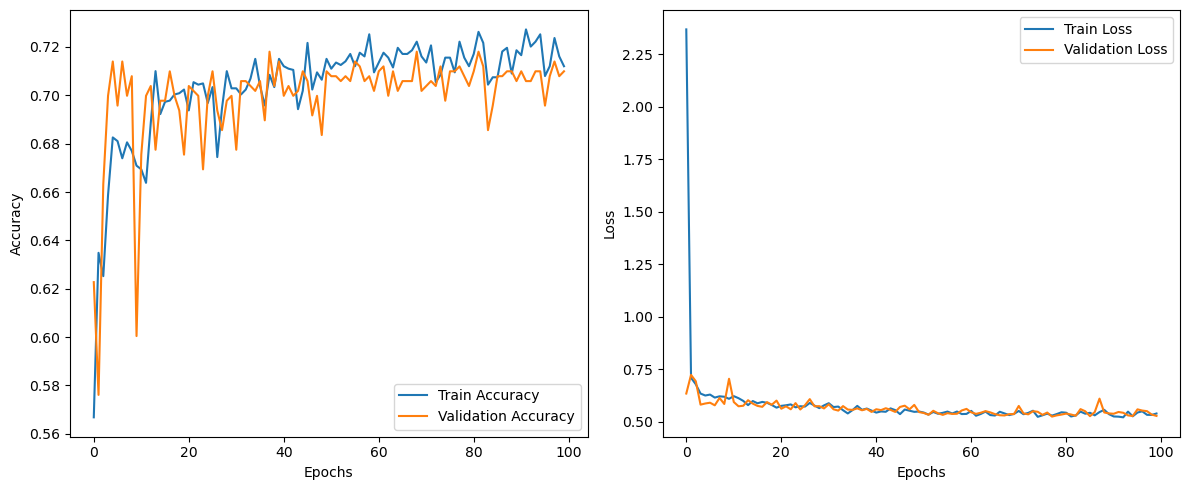

In [ ]:

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fixing the input shape and ensuring compatibility
input_features = X_train.shape[1]
def build_spectral_model(input_shape, units_1=512, units_2=256, dropout_rate=0.2, learning_rate=0.001):
    """
    Build a fully connected neural network for spectral features with a custom learning rate.
    """
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_shape,)),
        tf.keras.layers.Dense(units_1, activation='relu'),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(units_2, activation='relu'),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(1, activation='sigmoid')  # Binary classification
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),  # Set learning rate here
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Build and train model with custom learning rate
model = build_spectral_model(X_train.shape[1])


# Use this to build the model
model = build_spectral_model(input_features)



# Build and Train Model
print("Building and training model...")
model = build_spectral_model(X_train.shape[1])
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=32,
    verbose=1
)
# Evaluate Model
print("Evaluating model...")
y_pred = (model.predict(X_test) > 0.5).astype(int)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Spoof", "Bonafide"]))

# Plot Training History
def plot_training(history):
    plt.figure(figsize=(12, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training(history)

# **Dense Network with Augmentation**
The code extracts STFT and Mel-Spectrogram features and augments the data to improve model generalization. The dense network incorporates batch normalization and optimized dropout rates for better regularization and convergence. With a reduced learning rate, the training process achieves stability, and the augmented data boosts the model's robustness against noisy inputs. The model demonstrates improved classification performance, with precision and recall balanced across both classes.

1. **Training accuracy:** 99.11%
2. **Validation accuracy:** 87.83%
3.  **Overall accuracy:** ~88%

In [ ]:
import os
import numpy as np
import librosa
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
import matplotlib.pyplot as plt

# Paths and constants
AUDIO_PATH = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/Sample_Audio/"
CSV_FILE_PATH = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/output_file.csv"
SAMPLE_RATE = 16000
DURATION = 2  # seconds
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128

# Feature Extraction
def extract_spectral_features(file_path):
    try:
        # Load audio
        signal, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        signal = librosa.util.fix_length(signal, size=SAMPLE_RATE * DURATION)

        # Compute STFT
        stft = np.abs(librosa.stft(signal, n_fft=N_FFT, hop_length=HOP_LENGTH))

        # Compute Mel-Spectrogram
        mel_spec = librosa.feature.melspectrogram(S=stft, sr=sr, n_mels=N_MELS, hop_length=HOP_LENGTH)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

        # Flatten features
        features = mel_spec_db.flatten()
        return features
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset(audio_path, csv_file_path):
    labels_df = pd.read_csv(csv_file_path)
    X, y = [], []

    for _, row in labels_df.iterrows():
        file_name, label = row["filename"], row["label"]
        file_path = os.path.join(audio_path, file_name)
        if not os.path.exists(file_path):
            print(f"File not found: {file_name}")
            continue

        features = extract_spectral_features(file_path)
        if features is not None:
            X.append(features)
            y.append(1 if label == "bonafide" else 0)

    return np.array(X), np.array(y)

print("Loading data...")
X, y = load_dataset(AUDIO_PATH, CSV_FILE_PATH)

# Normalize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45)




Loading data...


Training Dense Network...
Epoch 1/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7008 - loss: 0.7144 - val_accuracy: 0.8215 - val_loss: 0.4165
Epoch 2/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8073 - loss: 0.4480 - val_accuracy: 0.8134 - val_loss: 0.4251
Epoch 3/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8280 - loss: 0.3942 - val_accuracy: 0.8053 - val_loss: 0.4647
Epoch 4/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8592 - loss: 0.3364 - val_accuracy: 0.8134 - val_loss: 0.4241
Epoch 5/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8661 - loss: 0.3128 - val_accuracy: 0.7911 - val_loss: 0.4602
Epoch 6/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8625 - loss: 0.3039 - val_accuracy: 0.8032 - val_loss: 0.4129
Epoch 7/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8930 - loss: 0.2640 - val_accuracy: 0.8418 - val_loss: 0.3687
Epoch 8/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9060

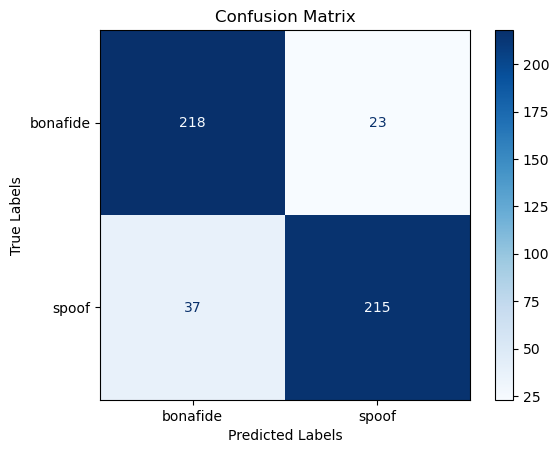

Model saved successfully!


In [ ]:
# Define Fully Connected Neural Network Model
def build_dense_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_shape,)),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.1),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model
# Build and Train Model
dense_model = build_dense_model(X_train.shape[1])

print("Training Dense Network...")
history = dense_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=16,
   # callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=35, restore_best_weights=True)],
    callbacks=[],  # No EarlyStopping

    verbose=1
)

# Evaluate Model
print("Evaluating the model...")
y_pred = (dense_model.predict(X_test, batch_size=16) > 0.5).astype(int)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(classification_report(y_test, y_pred, target_names=["bonafide", "spoof"]))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["bonafide", "spoof"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# Save the Model
dense_model.save("/Users/ananya/Desktop/Final_Project/spectral_features_dense_model.h5")
print("Model saved successfully!")
